<a href="https://colab.research.google.com/github/Sk-Naqeeb/MNIST_fashion_model_nn/blob/main/mnist_fashion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [2]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

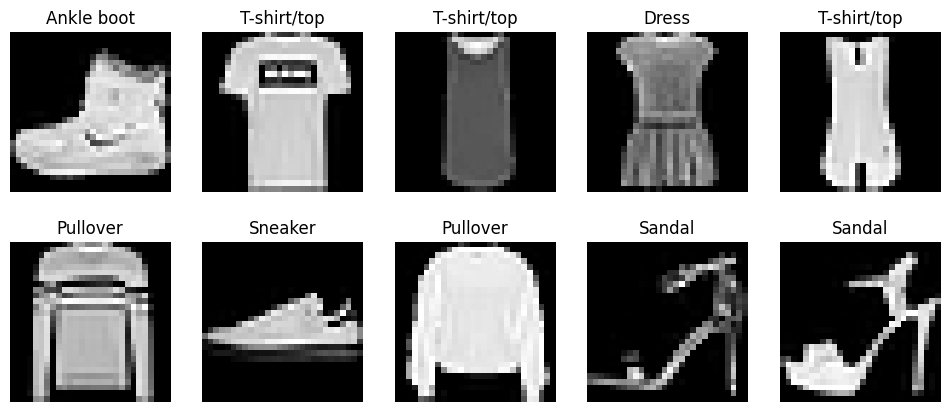

[6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")
plt.show()

print(np.bincount(y_train))  # check balance across the 10 classes

In [4]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [5]:
deep_nn = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(10)
])

deep_nn.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_dnn = deep_nn.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

deep_nn.evaluate(X_test, y_test)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.7745 - loss: 0.6204 - val_accuracy: 0.8382 - val_loss: 0.4368
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8412 - loss: 0.4402 - val_accuracy: 0.8535 - val_loss: 0.3899
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8519 - loss: 0.4068 - val_accuracy: 0.8762 - val_loss: 0.3543
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8627 - loss: 0.3799 - val_accuracy: 0.8752 - val_loss: 0.3384
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8663 - loss: 0.3639 - val_accuracy: 0.8698 - val_loss: 0.3389
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8709 - loss: 0.3514 - val_accuracy: 0.8790 - val_loss: 0.3225
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8757 - loss: 0.3403 - val_accuracy: 0.8765 - val_loss: 0.3286
Epoch 8/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8765 - loss: 0.3324 - val_accuracy: 0

[0.33447974920272827, 0.8788999915122986]

In [6]:
cnn = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Reshape((28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])

cnn.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

history_cnn = cnn.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

cnn.evaluate(X_test, y_test)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.8433 - loss: 0.4381 - val_accuracy: 0.8780 - val_loss: 0.3285
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8900 - loss: 0.2953 - val_accuracy: 0.8780 - val_loss: 0.3104
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9060 - loss: 0.2523 - val_accuracy: 0.9002 - val_loss: 0.2720
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9134 - loss: 0.2304 - val_accuracy: 0.9100 - val_loss: 0.2495
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9211 - loss: 0.2101 - val_accuracy: 0.8997 - val_loss: 0.2734
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9262 - loss: 0.1942 - val_accuracy: 0.9142 - val_loss: 0.2335
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9321 - loss: 0.1792 - val_accuracy: 0.9113 - val_loss: 0.2506
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9373 - loss: 0.1681 - val_accuracy: 

[0.2620308995246887, 0.9093000292778015]

CNN trained for 9 epochs


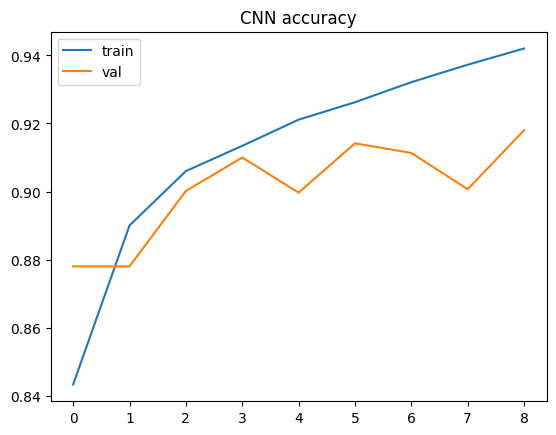

In [7]:
print(f"CNN trained for {len(history_cnn.history['loss'])} epochs")

plt.plot(history_cnn.history["accuracy"], label="train")
plt.plot(history_cnn.history["val_accuracy"], label="val")
plt.legend(); plt.title("CNN accuracy"); plt.show()

In [8]:
history_dnn = deep_nn.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)
deep_nn.evaluate(X_test, y_test)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8851 - loss: 0.3084 - val_accuracy: 0.8830 - val_loss: 0.3156
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8869 - loss: 0.3034 - val_accuracy: 0.8792 - val_loss: 0.3270
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8911 - loss: 0.2943 - val_accuracy: 0.8875 - val_loss: 0.3101
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8785 - loss: 0.3411


[0.3411046266555786, 0.8784999847412109]

In [10]:
cnn2 = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Reshape((28, 28, 1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10)
])

cnn2.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_cnn2 = cnn2.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

cnn2.evaluate(X_test, y_test)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.8044 - loss: 0.5585 - val_accuracy: 0.8840 - val_loss: 0.3063
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8695 - loss: 0.3610 - val_accuracy: 0.8992 - val_loss: 0.2688
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8877 - loss: 0.3089 - val_accuracy: 0.9093 - val_loss: 0.2423
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8987 - loss: 0.2833 - val_accuracy: 0.9100 - val_loss: 0.2413
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9059 - loss: 0.2613 - val_accuracy: 0.9192 - val_loss: 0.2290
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9119 - loss: 0.2438 - val_accuracy: 0.9210 - val_loss: 0.2100
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9152 - loss: 0.2308 - val_accuracy: 0.9198 - val_loss: 0.2300
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9209 - loss: 0.2201 - val_accuracy: 

[0.20848052203655243, 0.9259999990463257]

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step


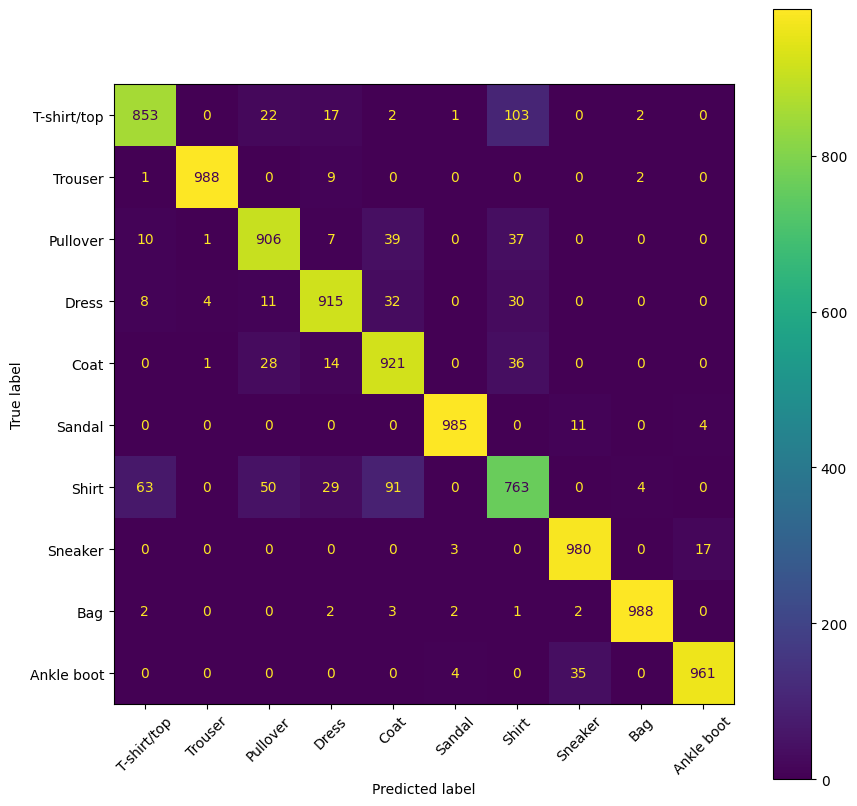

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred_cnn2 = np.argmax(tf.nn.softmax(cnn2.predict(X_test)), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn2)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45)
plt.show()